# Segmentasi Wilayah Pelanggan E-Commerce Shopee Berdasarkan Pola Pesanan, Pembayaran, dan Pengiriman Menggunakan K-Means dan Hierarchical Clustering

Proyek Akhir Praktikum Data Science, Prodi Informatika UPN "Veteran" Yogyakarta

Kelompok: `[AntechAntechAsync]`
### Anggota Kelompok:
* Joeseca Daniel (12324007)
* Afiq Fathurrahman (123240010)
* Ahmadsyah Anshori (123240020)
* M. Rofiq Mu'adz F (123240038)

## A. Business Understanding

### A.1 Judul dan Ruang Lingkup

**Judul:** Segmentasi Kota/Kabupaten Tujuan Pesanan pada Data Penjualan E-Commerce Shopee (Des 2023 – Nov 2025) Berdasarkan Pola Pesanan, Pembayaran, dan Pengiriman Menggunakan K-Means dan Hierarchical Clustering

| Unsur | Isi |
|---|---|
| Unit analisis | Kota/kabupaten tujuan pesanan (satu baris akhir = satu wilayah) |
| Periode data | 1 Desember 2023 – 30 November 2025 (24 bulan) |
| Variabel | Pola pesanan (jumlah, kuantitas, berat), pembayaran (COD, nilai transaksi, diskon), pengiriman (ongkir) |
| Metode | K-Means dan Agglomerative/Hierarchical Clustering (Modul 4 dan 5) |
| Di luar cakupan | Segmentasi pembeli individu (tidak ada ID pembeli), prediksi, dan forecasting |

**Keselarasan judul, tujuan, dan metrik:**

| Kata kunci judul | Diwujudkan sebagai | Dibuktikan dengan |
|---|---|---|
| Segmentasi kota/kabupaten | Clustering wilayah dengan batas minimal pesanan | Jumlah dan ukuran cluster |
| Pola pesanan | `jumlah_pesanan`, `rata_qty`, `rata_berat_gr` | Profil cluster |
| Pembayaran | `pct_cod`, `rata_total_bayar`, `rata_diskon` | Profil cluster |
| Pengiriman | `rata_ongkir` | Profil cluster |
| K-Means dan Hierarchical | Dua model dibandingkan pada fitur yang sama | Silhouette, Inertia, Cophenetic |

### A.2 Pernyataan Masalah dan Stakeholder

**Masalah.** Penjual melayani ratusan kota/kabupaten, tetapi kebijakan ongkir, promo, dan metode pembayaran cenderung seragam. Padahal pola belanja antarwilayah bisa berbeda (nilai transaksi, ongkir, preferensi COD, dan pembatalan). Tanpa segmentasi, promo ongkir bisa terbuang di wilayah yang tidak sensitif ongkir, sedangkan wilayah yang berisiko tinggi tidak mendapat perlakuan khusus.

| Stakeholder | Peran | Kepentingan |
|---|---|---|
| Pemilik/pengelola toko | Pengambil keputusan utama | Menentukan strategi promo, harga, dan kebijakan per wilayah |
| Tim logistik/operasional | Pengguna hasil | Memilih kurir dan merencanakan stok sesuai karakter wilayah |
| Tim pemasaran | Pengguna hasil | Menargetkan promo dan iklan per segmen |
| Analis data (kelompok kami) | Pembuat analisis | Menghasilkan segmen yang valid dan dapat dijelaskan |

*Catatan: dataset tidak menyebut pemilik atau penggunanya, sehingga stakeholder di atas adalah asumsi berdasarkan konteks penjualan e-commerce.*

### A.3 Tujuan (SMART)

| Unsur | Rumusan |
|---|---|
| **Specific** | Mengelompokkan kota/kabupaten dengan minimal `[isi batas, usulan 20]` pesanan ke dalam segmen berdasarkan 8 fitur agregat pesanan, pembayaran, dan pengiriman, lalu memberi profil dan nama tiap segmen |
| **Measurable** | Silhouette Score > 0,25 (batas minimal adanya struktur cluster), Cophenetic Correlation ≥ 0,70, tidak ada cluster di bawah 5% wilayah, dan setiap cluster punya minimal satu rekomendasi tindakan |
| **Achievable** | Memakai metode dari Modul 4 dan 5 pada ratusan baris agregat, yang ringan secara komputasi |
| **Relevant** | Hasil langsung mendukung keputusan promo ongkir, kebijakan COD, dan pemilihan kurir per wilayah |
| **Time-bound** | Seluruh analisis selesai dan repository dikumpulkan paling lambat 30 Oktober 2026 |

### A.4 Pertanyaan yang Ingin Dijawab
1. Berapa segmen wilayah yang terbentuk secara alami dari data pesanan?
2. Apa ciri tiap segmen (nilai transaksi, ongkir, berat, proporsi COD, tingkat pembatalan)?
3. Mana yang lebih baik dalam mengelompokkan wilayah, K-Means atau Hierarchical?
4. Strategi apa yang cocok untuk tiap segmen?

### A.5 Metrik Keberhasilan

| Metrik | Jenis | Cara ukur | Target | Alasan dipilih |
|---|---|---|---|---|
| Silhouette Score | Kualitas cluster | `silhouette_score(X_scaled, labels)` | > 0,25 (aturan praktis Kaufman & Rousseeuw: ≤ 0,25 berarti struktur tidak berarti) | Menilai kerapatan dan keterpisahan tanpa label asli |
| Inertia (Elbow) | Pemilihan K | `km.inertia_` untuk K = 2 sampai 10 | Titik siku | Dasar memilih jumlah cluster K-Means |
| Cophenetic Correlation | Kualitas dendrogram | `cophenet(Z, pdist(X_scaled))` | ≥ 0,70 | Menilai kesetiaan struktur hierarki terhadap jarak asli |
| Ukuran cluster | Keseimbangan | Proporsi wilayah per cluster | Tiap cluster ≥ 5% wilayah | Mencegah cluster yang hanya berisi segelintir wilayah |
| Stabilitas | Keandalan | K-Means diulang dengan beberapa `random_state` | Silhouette relatif stabil | Memastikan hasil bukan kebetulan inisialisasi |
| Interpretabilitas bisnis | Kegunaan | Profil cluster dapat dinamai dan punya rekomendasi | Semua cluster | Segmen yang tidak bisa dijelaskan tidak berguna bagi stakeholder |

*Target adalah acuan kerja. Bila hasil di bawah target, kami laporkan apa adanya dan jelaskan penyebabnya di bagian Evaluasi dan Konklusi.*

### A.6 Asumsi dan Batasan

**Asumsi**
1. Data berasal dari Shopee. Dataset tidak menyebut nama platform, tetapi ciri datanya (ShopeePay, SPayLater, SeaBank, kurir SPX) mengarah ke sana.
2. Setiap baris adalah satu pesanan unik (ID pesanan unik, tanpa duplikat).
3. Kota/kabupaten tujuan mencerminkan lokasi pembeli.
4. Wilayah dengan pesanan sedikit tidak cukup andal secara statistik, sehingga difilter pada batas minimal pesanan.
5. Pola belanja dianggap stabil sepanjang periode, sehingga data 24 bulan digabung tanpa dimensi waktu.

**Batasan**
1. Data hanya satu sumber di Kaggle, dan keterkaitannya dengan satu toko atau lebih tidak dapat dikonfirmasi (tidak ada kolom identitas toko). Hasil tidak dapat digeneralisasi ke seluruh pasar e-commerce Indonesia.
2. Tidak ada ID pembeli, sehingga segmentasi hanya bisa pada tingkat wilayah, bukan individu.
3. Clustering bersifat deskriptif dan tidak menjelaskan sebab-akibat.
4. K-Means sensitif terhadap outlier dan skala (Modul 4), sehingga perlu penanganan outlier dan `StandardScaler`.
5. Pesanan batal bernilai pembayaran 0, sehingga rata-rata nilai transaksi dihitung dari pesanan yang tidak batal.

### A.7 Risiko, Etika, dan Mitigasi

| Risiko | Kategori | Mitigasi |
|---|---|---|
| Wilayah dengan pesanan sedikit kurang terwakili sehingga profilnya tidak stabil | Bias data | Batas minimal pesanan per wilayah, dan jumlah wilayah serta pesanan yang tercakup dilaporkan |
| Data kemungkinan terkonsentrasi di wilayah tertentu | Bias sampel | Dicek di EDA, dan keterbatasannya ditulis di Konklusi |
| Segmen dipakai menilai individu (ecological fallacy) | Etika | Hasil hanya untuk keputusan tingkat wilayah, bukan untuk menilai pembeli |
| Segmen dipakai membatasi layanan (misalnya menolak COD) di wilayah tertentu secara tidak adil | Etika, diskriminasi | Rekomendasi bersifat insentif dan mitigasi, dan perlu ditinjau manusia sebelum diterapkan |
| Risiko identifikasi ulang dari wilayah kecil | Privasi | Tidak ada data pribadi (ID dianonimkan), analisis hanya pada level kota/kabupaten, dan wilayah kecil sudah difilter |
| Pelanggaran lisensi | Legal | Dataset berlisensi CC BY-SA 4.0, sehingga pembuat dan lisensi dicantumkan di README dan notebook |
| Kepatuhan perlindungan data | Legal | Dataset tidak memuat data pribadi sehingga tidak tunduk pada isu data pribadi menurut UU Pelindungan Data Pribadi (UU No. 27 Tahun 2022) |
| Cluster dipengaruhi outlier atau inisialisasi acak | Teknis | Penanganan outlier, `n_init=10`, `random_state=42`, dan perbandingan dua algoritma |

### A.8 Nilai Bisnis dan Use-Case

Segmen berikut adalah **hipotesis** contoh tindakan. Segmen aktual dan namanya ditentukan setelah clustering selesai.

| Contoh segmen (hipotesis) | Contoh tindakan | Nilai bisnis |
|---|---|---|
| Ongkir tinggi, nilai transaksi tinggi | Gratis ongkir dengan minimal belanja | Mendorong pesanan besar di wilayah jauh |
| Pesanan banyak, nilai kecil | Bundling dan voucher kuantitas | Menaikkan nilai per pesanan |
| COD tinggi, pembatalan tinggi | Dorong pembayaran digital, konfirmasi pesanan | Mengurangi pesanan batal dan biaya yang terbuang |
| Pesanan sedikit, nilai rendah | Promo uji coba, pemantauan | Menghindari biaya promo berlebih |

**Use-case utama:** dasar penentuan promo ongkir, kebijakan COD, dan pemilihan kurir per segmen wilayah. Dampak finansial tidak dapat diukur dari data ini dan memerlukan uji lanjutan (misalnya A/B test) di luar cakupan proyek.

### A.9 Pemetaan Stakeholder dan Data

| Stakeholder | Keputusan yang didukung | Kolom data yang dipakai | Fitur agregat | Keluaran untuk stakeholder |
|---|---|---|---|---|
| Pemilik toko | Kebijakan promo dan harga | `Total Pembayaran`, `Total Diskon` | `rata_total_bayar`, `rata_diskon` | Profil nilai transaksi per segmen |
| Tim logistik | Pemilihan kurir dan rencana stok | `Perkiraan Ongkos Kirim`, `total_weight_gr`, `Opsi Pengiriman` | `rata_ongkir`, `rata_berat_gr` | Karakter pengiriman per segmen |
| Tim pemasaran | Penargetan promo | `Kota/Kabupaten`, `total_qty` | `jumlah_pesanan`, `rata_qty` | Daftar wilayah per segmen |
| Pemilik dan operasional | Pengendalian pembatalan | `Metode Pembayaran`, `Status Pesanan` | `pct_cod`, `pct_batal` | Tingkat COD dan pembatalan per segmen (`pct_batal` dipakai untuk profil, bukan pembentuk cluster, supaya interpretasi tidak melingkar) |

### Metode
**K-Means** dan **Agglomerative/Hierarchical Clustering** (linkage ward, average, complete, single) sebagai pembanding, pada fitur agregat per wilayah yang telah distandardisasi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## B. Data Gathering

### Memuat data
File menggunakan pemisah `;` dan memiliki BOM di awal, sehingga dibaca dengan `sep=';'` dan `encoding='utf-8-sig'`.

In [3]:
df = pd.read_csv("data/all_months_clean.csv", sep=";", encoding="utf-8-sig")
print("Dimensi data (baris, kolom):", df.shape)
df.head()

Dimensi data (baris, kolom): (20848, 19)


,order_id,total_qty,total_weight_gr,total_returned_qty,Total Diskon,product_categories,num_product_categories,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Metode Pembayaran,Kota/Kabupaten,Provinsi,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Waktu Pesanan Dibuat,source_file
0,ORD_0000001,2,2000,0,0,Celengan,1,Selesai,NaN,Reguler (Cashless)-SPX Standard,Saldo ShopeePay,KOTA SERANG,BANTEN,0,10000,38300,10000,2024-04-01 00:15,AprilSales2024.xlsx
1,ORD_0000002,1,500,0,0,Celengan,1,Selesai,NaN,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA SEMARANG,JAWA TENGAH,0,14500,18576,14500,2024-04-01 01:47,AprilSales2024.xlsx
2,ORD_0000003,1,500,0,0,Celengan,1,Selesai,NaN,Hemat Kargo-SPX Hemat,SeaBank Bayar Instan,KAB. BOGOR,JAWA BARAT,0,8000,7069,8000,2024-04-01 04:25,AprilSales2024.xlsx
3,ORD_0000004,2,400,0,0,Mangkok Sambal / Saus,1,Selesai,NaN,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA JAMBI,JAMBI,0,20000,32200,20000,2024-04-01 04:41,AprilSales2024.xlsx
4,ORD_0000005,3,3600,0,0,"Keranjang, Other, Tempat Nasi",3,Batal,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA TANGERANG,BANTEN,0,0,0,8000,2024-04-01 06:12,AprilSales2024.xlsx


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20848 entries, 0 to 20847
Data columns (total 19 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   order_id                            20848 non-null  object
 1   total_qty                           20848 non-null  int64 
 2   total_weight_gr                     20848 non-null  int64 
 3   total_returned_qty                  20848 non-null  int64 
 4   Total Diskon                        20848 non-null  int64 
 5   product_categories                  20848 non-null  object
 6   num_product_categories              20848 non-null  int64 
 7   Status Pesanan                      20848 non-null  object
 8   Alasan Pembatalan                   2830 non-null   object
 9   Opsi Pengiriman                     20848 non-null  object
 10  Metode Pembayaran                   20848 non-null  object
 11  Kota/Kabupaten                      20848 non-null  ob

### Sumber dan lisensi
- Sumber: Kaggle, `[isi judul dataset]`
- Tautan: `[isi URL Kaggle]`
- Pembuat dataset: `[isi nama]`
- Lisensi: `[isi lisensi dari halaman Kaggle]`
- Tanggal pengambilan: `[isi tanggal unduh]`

### Pengertian dataset
Dataset berisi pesanan dari **transaksi e-commerce Indonesia yang berdasarkan ciri datanya berasal dari Shopee**, dengan periode `[isi periode sebenarnya dari data, lihat sel EDA]`. Setiap baris adalah satu pesanan. Dataset tidak memuat identitas pembeli (nama atau alamat lengkap), hanya kota/kabupaten dan provinsi. Dataset ini dipilih karena `[isi alasan kelompok]`.

Karena hanya mewakili satu toko di satu platform, hasil analisis tidak dapat digeneralisasi ke seluruh pasar e-commerce Indonesia.

### Arti kolom
*(Cocokkan dengan deskripsi kolom di halaman Kaggle, lalu perbaiki bila berbeda.)*

| Kolom | Arti |
|---|---|
| `order_id` | ID pesanan (identitas baris, bukan fitur) |
| `total_qty` | Total kuantitas produk dalam pesanan |
| `total_weight_gr` | Total berat pesanan (gram) |
| `total_returned_qty` | Kuantitas produk yang dikembalikan |
| `Total Diskon` | Total diskon pada pesanan |
| `product_categories` | Kategori produk dalam pesanan (bisa gabungan) |
| `num_product_categories` | Jumlah kategori produk dalam pesanan |
| `Status Pesanan` | Status akhir pesanan (selesai, batal, dikirim, dll.) |
| `Alasan Pembatalan` | Alasan pembatalan (hanya terisi untuk pesanan batal) |
| `Opsi Pengiriman` | Layanan kurir yang dipilih |
| `Metode Pembayaran` | Cara pembayaran (COD, ShopeePay, dll.) |
| `Kota/Kabupaten` | Wilayah tujuan pengiriman |
| `Provinsi` | Provinsi tujuan |
| `Ongkos Kirim Dibayar oleh Pembeli` | Ongkir yang dibayar pembeli |
| `Estimasi Potongan Biaya Pengiriman` | Estimasi potongan biaya kirim |
| `Total Pembayaran` | Total yang dibayar pembeli |
| `Perkiraan Ongkos Kirim` | Perkiraan ongkos kirim dari platform |
| `Waktu Pesanan Dibuat` | Waktu pesanan dibuat |
| `source_file` | Nama file ekspor bulanan asal baris (metadata, bukan fitur) |

## C. Exploratory Data Analysis (EDA)

### C.1 Statistik deskriptif

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
total_qty,20848.0,2.560821,7.796763,1.0,1.0,1.0,2.0,256.0
total_weight_gr,20848.0,2004.529691,7106.357515,10.0,300.0,500.0,1600.0,375000.0
total_returned_qty,20848.0,0.017748,0.548656,0.0,0.0,0.0,0.0,70.0
Total Diskon,20848.0,405.199348,9784.017705,0.0,0.0,0.0,0.0,700000.0
num_product_categories,20848.0,1.112097,0.485361,1.0,1.0,1.0,1.0,11.0
Ongkos Kirim Dibayar oleh Pembeli,20848.0,4189.990695,13578.489678,0.0,0.0,0.0,3000.0,584000.0
Estimasi Potongan Biaya Pengiriman,20848.0,10722.539284,12672.471066,0.0,0.0,9500.0,15000.0,312000.0
Total Pembayaran,20848.0,50683.597036,144019.263221,0.0,13480.0,21800.0,41600.0,3403591.0
Perkiraan Ongkos Kirim,20848.0,18425.626343,23791.508665,1.0,8000.0,11000.0,20000.0,959200.0


**Temuan:** `[isi dengan kata-kata sendiri setelah melihat output: rentang nilai, selisih mean dan median, tanda adanya outlier]`

### C.2 Missing value dan duplikat

In [ ]:
na = df.isna().sum()
na_pct = (na / len(df) * 100).round(2)
display(pd.DataFrame({"jumlah_kosong": na, "persen": na_pct})[na > 0])
print("Baris duplikat penuh:", df.duplicated().sum())
print("order_id duplikat:", df["order_id"].duplicated().sum())

,jumlah_kosong,persen
Alasan Pembatalan,18018,86.43
Waktu Pesanan Dibuat,1980,9.50


Baris duplikat penuh: 0
order_id duplikat: 0


**Temuan:** `[isi: kolom mana yang kosong, apakah kosong secara struktural (Alasan Pembatalan) atau karena data hilang (Waktu Pesanan Dibuat), dan rencana penanganannya di bagian D]`

### C.3 Periode data

Awal: 2023-12-01 00:33:00 | Akhir: 2025-11-30 23:17:00
Waktu tidak terbaca: 1980


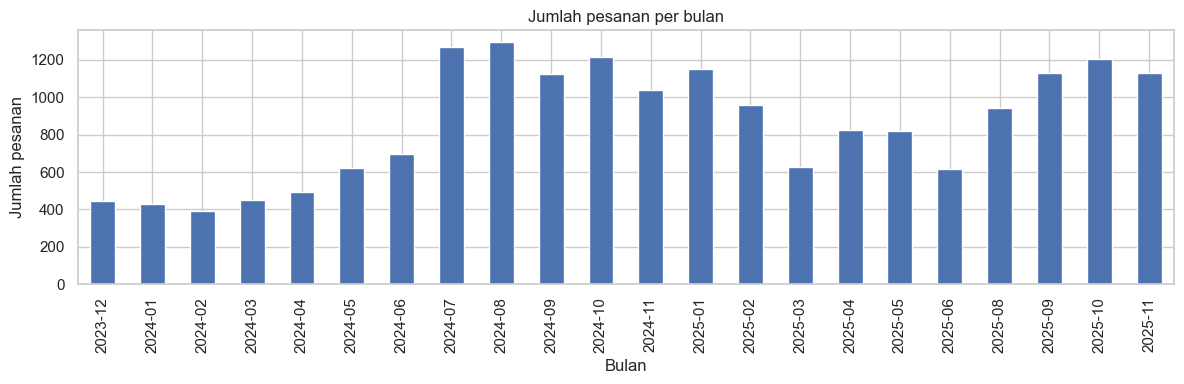

In [ ]:
df["waktu"] = pd.to_datetime(df["Waktu Pesanan Dibuat"], errors="coerce")
print("Awal:", df["waktu"].min(), "| Akhir:", df["waktu"].max())
print("Waktu tidak terbaca:", df["waktu"].isna().sum())

per_bulan = df.groupby(df["waktu"].dt.to_period("M")).size()
plt.figure(figsize=(12, 4))
per_bulan.plot(kind="bar")
plt.title("Jumlah pesanan per bulan")
plt.xlabel("Bulan"); plt.ylabel("Jumlah pesanan")
plt.tight_layout(); plt.show()

**Temuan:** `[isi: periode sebenarnya, bulan dengan pesanan tertinggi, bulan yang hilang atau kosong]`

### C.4 Status pesanan, pembayaran, dan pengiriman

status_ringkas
Selesai             17768
Batal                2830
Pesanan diterima      161
Sedang Dikirim         59
Telah Dikirim          30
Name: count, dtype: int64

Metode Pembayaran
COD (Bayar di Tempat)        11538
Saldo ShopeePay               3692
Online Payment                3170
SPayLater                     1485
SeaBank Bayar Instan           637
Kartu Kredit/Debit             222
Indomaret/i.Saku                43
Alfamart/Alfamidi/Dan+Dan       36
Pembayaran dibebaskan           18
Cicilan Kartu Kredit             3
BCA OneKlik                      3
Mitra Shopee                     1
Name: count, dtype: int64

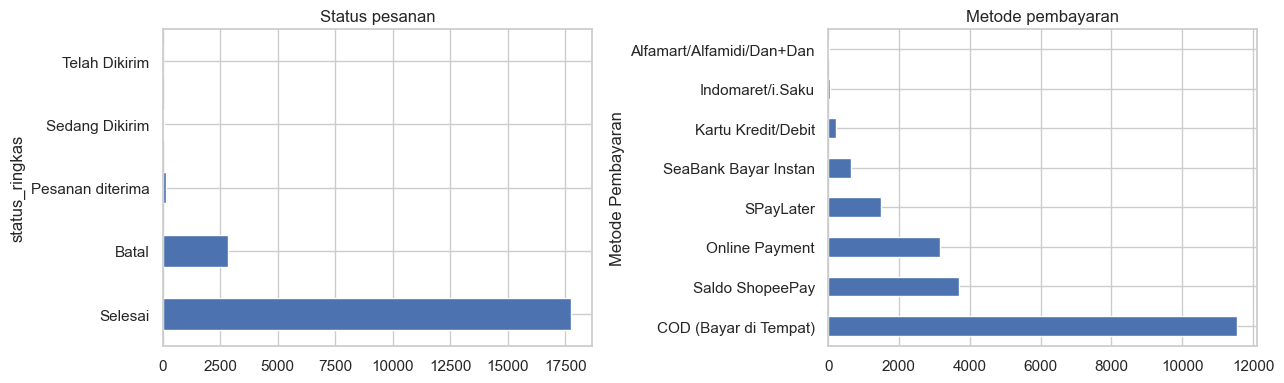

In [ ]:
df["status_ringkas"] = df["Status Pesanan"].str.split(",").str[0].str.strip()
display(df["status_ringkas"].value_counts())
display(df["Metode Pembayaran"].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["status_ringkas"].value_counts().head(6).plot(kind="barh", ax=ax[0], title="Status pesanan")
df["Metode Pembayaran"].value_counts().head(8).plot(kind="barh", ax=ax[1], title="Metode pembayaran")
plt.tight_layout(); plt.show()

**Temuan:** `[isi: proporsi pesanan batal, dominasi COD, label status yang tidak konsisten]`

In [ ]:
df["kurir"] = (df["Opsi Pengiriman"].str.upper()
               .str.extract(r"(SPX|JNE|J&T|GOSEND|GRABEXPRESS)", expand=False))
display(df["kurir"].value_counts(dropna=False))
display(df["Opsi Pengiriman"].nunique())

kurir
SPX            18785
NaN              765
JNE              602
J&T              600
GOSEND            70
GRABEXPRESS       26
Name: count, dtype: int64

45

**Temuan:** `[isi: kurir dominan, dan bahwa Opsi Pengiriman punya banyak label ganda untuk layanan yang sama]`

### C.5 Sebaran wilayah

Jumlah kota/kabupaten: 424
Jumlah provinsi: 34


Kota/Kabupaten
KAB. BOGOR                1193
KAB. TANGERANG            1135
KOTA TANGERANG            1011
KAB. BEKASI                813
KOTA TANGERANG SELATAN     802
KOTA JAKARTA BARAT         729
KOTA JAKARTA SELATAN       695
KOTA JAKARTA TIMUR         680
KOTA BEKASI                623
KOTA DEPOK                 598
Name: count, dtype: int64

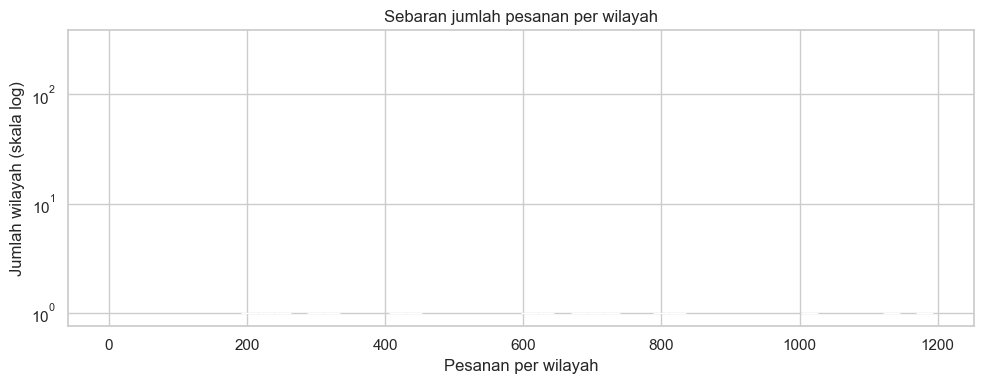

Minimal  5 pesanan -> 317 wilayah, mencakup 98.8% pesanan
Minimal 10 pesanan -> 238 wilayah, mencakup 96.3% pesanan
Minimal 20 pesanan -> 163 wilayah, mencakup 91.2% pesanan
Minimal 30 pesanan -> 111 wilayah, mencakup 85.2% pesanan
Minimal 50 pesanan ->  70 wilayah, mencakup 77.8% pesanan


In [ ]:
print("Jumlah kota/kabupaten:", df["Kota/Kabupaten"].nunique())
print("Jumlah provinsi:", df["Provinsi"].nunique())
per_wilayah = df["Kota/Kabupaten"].value_counts()
display(per_wilayah.head(10))

plt.figure(figsize=(10, 4))
sns.histplot(per_wilayah, bins=50, log_scale=(False, True))
plt.title("Sebaran jumlah pesanan per wilayah")
plt.xlabel("Pesanan per wilayah"); plt.ylabel("Jumlah wilayah (skala log)")
plt.tight_layout(); plt.show()

for t in [5, 10, 20, 30, 50]:
    s = per_wilayah[per_wilayah >= t]
    print(f"Minimal {t:>2} pesanan -> {len(s):>3} wilayah, mencakup {s.sum()/len(df)*100:.1f}% pesanan")

**Temuan:** `[isi: distribusi sangat timpang, dan alasan memilih batas minimal pesanan per wilayah untuk bagian D]`

### C.6 Outlier pada fitur numerik

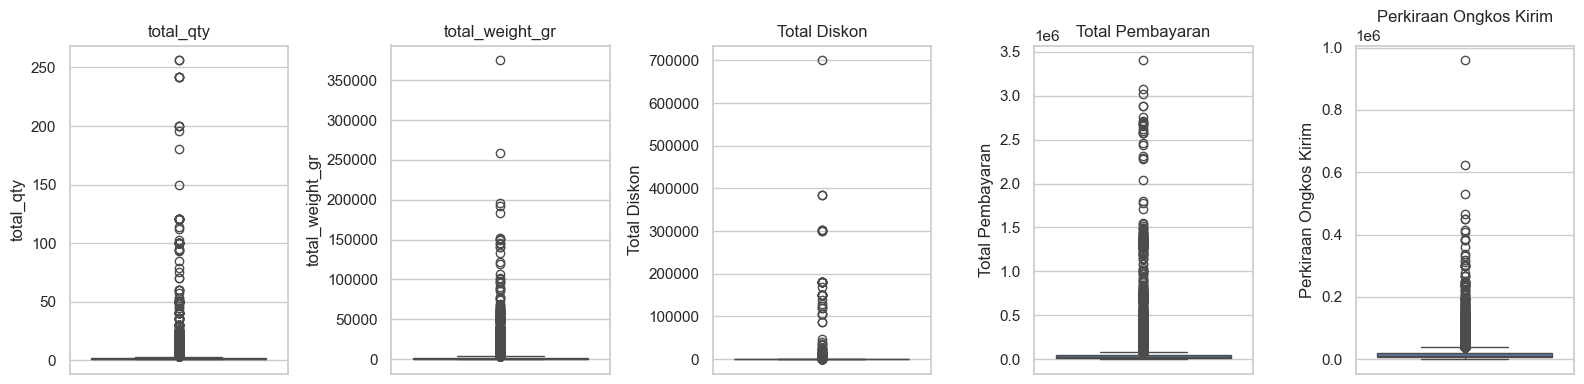

total_qty                  outlier IQR: 2614 (12.5%)
total_weight_gr            outlier IQR: 2448 (11.7%)
Total Diskon               outlier IQR: 135 (0.6%)
Total Pembayaran           outlier IQR: 2309 (11.1%)
Perkiraan Ongkos Kirim     outlier IQR: 1815 (8.7%)


In [ ]:
num_cols = ["total_qty", "total_weight_gr", "Total Diskon", "Total Pembayaran", "Perkiraan Ongkos Kirim"]
fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f"{c:<26} outlier IQR: {n} ({n/len(df)*100:.1f}%)")

**Temuan:** `[isi: kolom mana yang paling banyak outlier dan apa artinya bagi K-Means yang sensitif terhadap outlier]`

### C.7 Kebocoran dan keterkaitan antarvariabel

,count,mean,std,min,25%,50%,75%,max
status_ringkas,,,,,,,,
Batal,2830.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Pesanan diterima,161.0,36743.0,43356.0,5499.0,16682.0,20998.0,35377.0,382480.0
Sedang Dikirim,59.0,75233.0,157269.0,5135.0,17700.0,34998.0,63548.0,1148600.0
Selesai,17768.0,58845.0,154137.0,0.0,17640.0,26128.0,47500.0,3403591.0
Telah Dikirim,30.0,24886.0,20030.0,7000.0,14850.0,17500.0,33000.0,111900.0


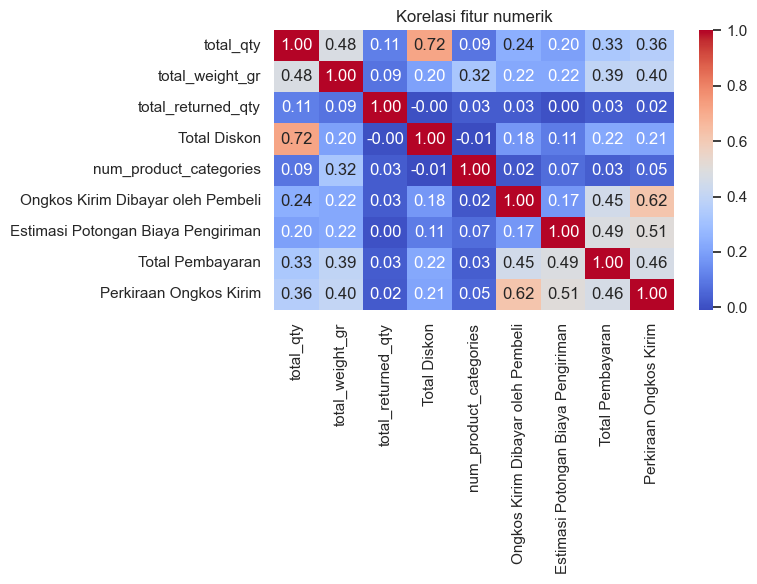

In [ ]:
display(df.groupby("status_ringkas")["Total Pembayaran"].describe().round(0))

plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasi fitur numerik")
plt.tight_layout(); plt.show()

**Temuan:** `[isi: nilai Total Pembayaran pada pesanan batal, fitur yang berkorelasi tinggi, dan implikasinya pada pemilihan fitur]`

## D. Cleaning dan Preprocessing

*(Isi setelah EDA selesai. Tampilkan kondisi data **sebelum dan sesudah** tiap langkah.)*

- [ ] D.1 Penanganan duplikat dan missing value
- [ ] D.2 Konversi tipe data (waktu) dan penyeragaman `Status Pesanan` dan `Opsi Pengiriman`
- [ ] D.3 Keputusan status yang dikeluarkan ("Sedang Dikirim", "Telah Dikirim")
- [ ] D.4 Agregasi per wilayah (`groupby('Kota/Kabupaten').agg(...)`) dan batas minimal pesanan
- [ ] D.5 Penanganan outlier dan skewness (IQR, transformasi log)
- [ ] D.6 Feature selection: fitur yang dipakai, dibuang, dan dibuat, beserta alasannya
- [ ] D.7 Scaling dengan `StandardScaler`

## E. Modelling

- [ ] E.1 Elbow Method dan Silhouette Score untuk K = 2 sampai 10
- [ ] E.2 K-Means (`n_init=10`, `random_state=42`)
- [ ] E.3 Agglomerative Clustering dengan linkage ward, average, complete, single
- [ ] E.4 Dendrogram (ward) dan penentuan jumlah cluster dari lompatan tinggi merge

## F. Evaluasi

- [ ] F.1 Tabel Silhouette Score semua model
- [ ] F.2 Cophenetic Correlation Coefficient tiap linkage
- [ ] F.3 Heatmap z-score fitur yang diurutkan per cluster
- [ ] F.4 Profil tiap cluster (`groupby`, `crosstab`)
- [ ] F.5 Perbandingan K-Means vs Hierarchical dan alasan memilih model terbaik

## G. Konklusi

- [ ] Jawaban atas empat pertanyaan di Business Understanding
- [ ] Penamaan tiap segmen wilayah dan terjemahan temuan ke bahasa bisnis
- [ ] Rekomendasi strategi per segmen
- [ ] Keputusan yang diambil
- [ ] Keterbatasan (satu toko, satu platform, jumlah wilayah, outlier)